# Práctica PLN mediante Deep Learning 26/27 — Multi-Author Writing Style Analysis (PAN 2026)

**Integrantes:**
- Miriam Bernat
- [Integrante 2]

## Tabla resumen de experimentos

> Se rellena al final con los valores de `artifacts/results.csv` (ver sección 6). Métrica: **macro F1** sobre todos los pares de frases consecutivas del split de **test**, con umbral de decisión elegido en **validación**.

| ID | Experimento | Easy | Medium | Hard | Conclusión |
|---|---|---|---|---|---|
| B0 | Siempre "sin cambio" | | | | |
| B0r | Aleatorio con la tasa a priori | | | | |
| B1-LR | Rasgos estilométricos + similitudes TF-IDF, regresión logística | | | | |
| B1-HGB | Ídem con gradient boosting | | | | |
| B2 | Similitud de embeddings de frase | | | | |
| T1 | Fine-tuning cross-encoder (pares) | | | | |
| P1 | Propuesta original | | | | |

## Metodología experimental

1. **Tarea:** para cada par de frases consecutivas de un documento, predecir si cambia el autor (1) o no (0). Tres datasets independientes (easy / medium / hard) con la partición oficial 70 / 15 / 15.
2. **Protocolo:** se entrena con *train* (submuestreado cuando el coste lo exige), se eligen hiperparámetros y umbral de decisión en *validation* y se informa la métrica final en *test* (tenemos sus etiquetas en local). Nunca se usa test para decidir nada.
3. **Métrica:** macro F1 sobre todos los pares del split (métrica oficial de PAN). Se informa por nivel.
4. **Progresión:** baselines triviales → baselines clásicos (estilometría) → embeddings → fine-tuning de Transformer estándar → propuesta original. Todos los experimentos, incluidos los fallidos, se conservan en el notebook.
5. **Comparación externa:** con los resultados publicados por los participantes de PAN para la misma tarea (sección 5).

## 1. Preparación

### 1.1 Configuración
`RUN_TRAINING = False` permite reejecutar el notebook cargando modelos y predicciones guardados en `artifacts/` sin volver a entrenar.

In [7]:
import json
import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import f1_score

DATA_DIR = Path("full_dataset")
ART_DIR = Path("artifacts")
ART_DIR.mkdir(exist_ok=True)

LEVELS = ["easy", "medium", "hard"]
SPLITS = ["train", "validation", "test"]
SEED = 42
RUN_TRAINING = True

random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

### 1.2 Carga del dataset
Cada problema es un `problem-X.txt` con **una frase por línea** y un `truth-problem-X.json` con `authors` y `changes` (una etiqueta por par de frases consecutivas).

Detalles comprobados al explorar los ficheros:
- Se leen con `newline=""` como indica la organización de PAN.
- Hay que separar por `"\n"` y **no** con `str.splitlines()`: esta última también corta en caracteres como `\u2028` (separador de línea Unicode) o `\x85` que aparecen dentro de algunas frases, y en 24 documentos rompía la correspondencia `len(changes) == n_frases - 1`. Con `split("\n")` la correspondencia se cumple en los 45.000 documentos (se verifica con un `assert`).

In [8]:
def read_problem(txt_path):
    with open(txt_path, "r", encoding="utf-8", newline="") as f:
        text = f.read()
    return text.rstrip("\n").split("\n")


def load_split(level, split):
    folder = DATA_DIR / level / split
    docs = []
    for txt in sorted(folder.glob("problem-*.txt"), key=lambda p: int(p.stem.split("-")[1])):
        sentences = read_problem(txt)
        truth = json.loads((folder / f"truth-{txt.stem}.json").read_text(encoding="utf-8"))
        assert len(truth["changes"]) == len(sentences) - 1, txt
        docs.append({"id": txt.stem, "sentences": sentences,
                     "changes": truth["changes"], "authors": truth["authors"]})
    return docs


data = {lvl: {sp: load_split(lvl, sp) for sp in SPLITS} for lvl in LEVELS}
{lvl: {sp: len(docs) for sp, docs in splits.items()} for lvl, splits in data.items()}

{'easy': {'train': 10500, 'validation': 2250, 'test': 2250},
 'medium': {'train': 10500, 'validation': 2250, 'test': 2250},
 'hard': {'train': 10500, 'validation': 2250, 'test': 2250}}

### 1.3 Análisis exploratorio

In [9]:
def segment_lengths(doc):
    # Longitud (en frases) de cada tramo consecutivo escrito por el mismo autor
    cuts = [i + 1 for i, c in enumerate(doc["changes"]) if c]
    bounds = [0] + cuts + [len(doc["sentences"])]
    return np.diff(bounds)


rows = []
for lvl in LEVELS:
    for sp in SPLITS:
        docs = data[lvl][sp]
        n_sent = np.array([len(d["sentences"]) for d in docs])
        changes = np.concatenate([d["changes"] for d in docs])
        seg = np.concatenate([segment_lengths(d) for d in docs])
        rows.append({
            "nivel": lvl, "split": sp, "docs": len(docs),
            "frases/doc media": n_sent.mean(), "frases/doc min": n_sent.min(), "frases/doc max": n_sent.max(),
            "pares": len(changes), "% cambios": 100 * changes.mean(),
            "autores media": np.mean([d["authors"] for d in docs]),
            "long. tramo media": seg.mean(), "% tramos de 1 frase": 100 * (seg == 1).mean(),
        })
eda = pd.DataFrame(rows)
eda.round(2)

,nivel,split,docs,frases/doc media,frases/doc min,frases/doc max,pares,% cambios,autores media,long. tramo media,% tramos de 1 frase
0,easy,train,10500,53.36,2,162,549804,30.52,3.0,3.14,85.65
1,easy,validation,2250,53.19,2,154,117435,30.29,3.0,3.16,85.70
2,easy,test,2250,53.25,2,159,117569,30.50,3.0,3.14,85.50
3,medium,train,10500,124.75,13,175,1299324,4.36,3.0,19.51,34.92
4,medium,validation,2250,124.99,12,166,278988,4.38,3.0,19.43,35.43
5,medium,test,2250,125.03,13,164,279060,4.33,3.0,19.61,35.08
6,hard,train,10500,57.19,5,169,589946,20.94,3.0,4.48,41.66
7,hard,validation,2250,57.61,7,164,127380,21.25,3.0,4.42,41.60
8,hard,test,2250,57.55,7,157,127237,21.08,3.0,4.45,41.52


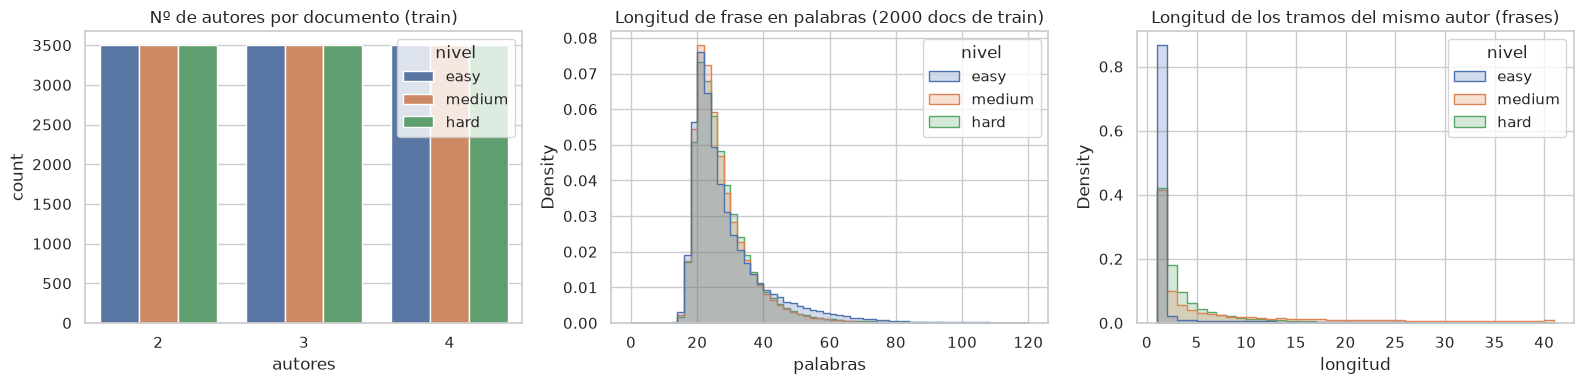

,count,mean,std,min,50%,95%,99%,max
nivel,,,,,,,,
easy,106036.0,29.2,14.5,1.0,25.0,56.0,83.0,821.0
hard,111917.0,27.5,10.9,12.0,25.0,45.0,67.0,496.0
medium,249259.0,26.8,9.3,5.0,24.0,44.0,60.0,301.0


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

authors = pd.DataFrame([{"nivel": lvl, "autores": d["authors"]}
                        for lvl in LEVELS for d in data[lvl]["train"]])
sns.countplot(data=authors, x="autores", hue="nivel", ax=axes[0])
axes[0].set_title("Nº de autores por documento (train)")

sent_len = pd.DataFrame([{"nivel": lvl, "palabras": len(s.split())}
                         for lvl in LEVELS for d in data[lvl]["train"][:2000] for s in d["sentences"]])
sns.histplot(data=sent_len, x="palabras", hue="nivel", bins=60, binrange=(0, 120),
             stat="density", common_norm=False, element="step", ax=axes[1])
axes[1].set_title("Longitud de frase en palabras (2000 docs de train)")

segs = pd.DataFrame([{"nivel": lvl, "longitud": int(l)}
                     for lvl in LEVELS for d in data[lvl]["train"] for l in segment_lengths(d)])
sns.histplot(data=segs, x="longitud", hue="nivel", bins=40, binrange=(1, 41),
             stat="density", common_norm=False, element="step", ax=axes[2])
axes[2].set_title("Longitud de los tramos del mismo autor (frases)")
plt.tight_layout()
plt.show()

sent_len.groupby("nivel")["palabras"].describe(percentiles=[0.5, 0.95, 0.99]).round(1)

In [11]:
# Ejemplos de pares con y sin cambio en el nivel difícil
doc = data["hard"]["train"][0]
for i, c in enumerate(doc["changes"][:12]):
    print(f"[{'CAMBIO' if c else '  =   '}] {doc['sentences'][i][:90]!r}\n          -> {doc['sentences'][i + 1][:90]!r}\n")

[  =   ] 'I see pictures of me on the wall, and I recognize my face, but for the life of me I don’t '
          -> '“We were kids, kids are dumb that way.” \xa0 \xa0 \xa0 \xa0 \xa0 \xa0\xa0“Or maybe just HE was.” \xa0 \xa0 \xa0 \xa0 \xa0 \xa0\xa0Hu'

[CAMBIO] '“We were kids, kids are dumb that way.” \xa0 \xa0 \xa0 \xa0 \xa0 \xa0\xa0“Or maybe just HE was.” \xa0 \xa0 \xa0 \xa0 \xa0 \xa0\xa0Hu'
          -> 'Although that’s so adorable I’m gonna tease them.” Hunk laughs merrily, his laugh ringing '

[CAMBIO] 'Although that’s so adorable I’m gonna tease them.” Hunk laughs merrily, his laugh ringing '
          -> '“HUNK, I can hear you, you’re not supposed to laugh at jokes like that” Lance calls across'

[CAMBIO] '“HUNK, I can hear you, you’re not supposed to laugh at jokes like that” Lance calls across'
          -> '“Aw, c’mon Lance, you like anime, so really he’s nothing compared to you.” Hunk teases, gr'

[CAMBIO] '“Aw, c’mon Lance, you like anime, so really he’s nothing compared to y

**Observaciones:**
- **Tamaño:** 10.500 / 2.250 / 2.250 documentos por nivel. *medium* tiene documentos más largos (~125 frases frente a ~53–57), lo que supone 1,3 M pares en train.
- **Desbalance:** hay un 30,5 % de cambios en *easy*, un 21 % en *hard* y solo un 4,4 % en *medium*. Predecir siempre 0 ya da macro F1 ≈ 0,49 en *medium*, así que hacen falta pesos por clase y ajuste del umbral de decisión. *Accuracy* no es informativa.
- **Autores:** prácticamente todos los documentos tienen 3 autores.
- **Tramos del mismo autor:** en *easy* el 85 % son de una sola frase (el autor cambia casi en cada frase). En *hard* lo son el 42 % y en *medium* el 35 %, con tramos de ~19 frases de media. El contexto de frases vecinas del mismo autor es escaso en *easy* y abundante en *medium*.
- **Longitud de frase:** mediana de ~25 palabras y p99 entre 60 y 83 palabras según el nivel, con algunos valores atípicos (hasta 821 palabras). Un par de frases cabe en 128 tokens en la gran mayoría de los casos (se verifica en la sección 3).

### 1.4 Representación en pares y utilidades de evaluación
Todos los modelos trabajan sobre la lista plana de pares `(frase_i, frase_i+1)` de cada split.
La macro F1 se calcula **concatenando todos los pares del split**, igual que el evaluador oficial.

In [12]:
def flatten(docs):
    # Lista plana de frases e índices (ia, ib) de cada par consecutivo
    sents, ia, ib, y, doc_idx = [], [], [], [], []
    for k, d in enumerate(docs):
        off, n = len(sents), len(d["sentences"])
        sents.extend(d["sentences"])
        ia.extend(range(off, off + n - 1))
        ib.extend(range(off + 1, off + n))
        y.extend(d["changes"])
        doc_idx.extend([k] * (n - 1))
    return sents, np.array(ia), np.array(ib), np.array(y), np.array(doc_idx)


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")


def best_threshold(y_true, probs, grid=np.linspace(0.02, 0.98, 97)):
    scores = [macro_f1(y_true, (probs >= t).astype(int)) for t in grid]
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])


RESULTS_CSV = ART_DIR / "results.csv"
results = pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame(
    columns=["exp", "nivel", "split", "macro_f1", "notas"])


def log_result(exp, level, split, f1, notes=""):
    # Sustituye la fila si el experimento ya estaba registrado
    global results
    mask = (results["exp"] == exp) & (results["nivel"] == level) & (results["split"] == split)
    row = pd.DataFrame([{"exp": exp, "nivel": level, "split": split, "macro_f1": round(f1, 4), "notas": notes}])
    results = pd.concat([results[~mask], row], ignore_index=True)
    results.to_csv(RESULTS_CSV, index=False)


def show_results(split="test"):
    r = results[results["split"] == split]
    return r.pivot_table(index="exp", columns="nivel", values="macro_f1", sort=False)[LEVELS]

## 2. Baselines

### 2.1 B0: baselines triviales
- **B0:** predecir siempre "sin cambio". Es la cota inferior que cualquier modelo debe superar.
- **B0r:** predicción aleatoria con la tasa de cambios de train.

In [13]:
rng = np.random.default_rng(SEED)
for lvl in LEVELS:
    prior = np.concatenate([d["changes"] for d in data[lvl]["train"]]).mean()
    for sp in ["validation", "test"]:
        y = np.concatenate([d["changes"] for d in data[lvl][sp]])
        log_result("B0", lvl, sp, macro_f1(y, np.zeros_like(y)), "siempre 0")
        log_result("B0r", lvl, sp, macro_f1(y, (rng.random(len(y)) < prior).astype(int)), f"p={prior:.3f}")
show_results()

nivel,easy,medium,hard
exp,,,
B1-LR,0.9905,0.5736,0.6301
B1-HGB,0.9907,0.5842,0.6403
B0,0.4100,0.4889,0.4411
B0r,0.5012,0.4997,0.5011


### 2.2 B1: rasgos estilométricos + similitudes TF-IDF

Rasgos clásicos de estilometría calculados por frase:
- **Longitud y léxico:** caracteres, palabras, longitud media de palabra, riqueza léxica (type-token ratio), proporción de mayúsculas, dígitos y palabras capitalizadas.
- **Contracciones:** `n't`, `'s`, etc. Son muy dependientes del autor.
- **Puntuación:** frecuencia relativa de cada signo, distinguiendo comillas y apóstrofos rectos (`' "`) de los tipográficos (`’ “ ”`) y los distintos guiones (`- – —`). Es un rasgo de "formato" típico del autor o de su editor de texto.
- **Palabras funcionales:** frecuencia relativa de unas 50 palabras funcionales. Son independientes del tema, lo que es clave en *hard*.
- **Final de frase:** con qué carácter acaba.

Para cada par se usa `|f_i - f_j|` (cuánto difieren) y `(f_i + f_j) / 2` (contexto). Se añaden dos similitudes coseno:
- **TF-IDF de n-gramas de caracteres** (2–4): captura estilo y ortografía.
- **TF-IDF de palabras sin stopwords:** captura el tema; debería ayudar en *easy* y poco en *hard*.

Por coste se entrena con una muestra de `N_TRAIN_DOCS` documentos por nivel. Se evalúa sobre validation y test completos.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

N_TRAIN_DOCS = 3000

FUNCTION_WORDS = ("the a an and but or nor so yet of to in on at by for with from about into over after "
                  "as that this these those which who whom whose what when where why how it its he she they "
                  "we you i me him her them us my your his their our is was were be been are am have has had "
                  "do does did not no if then than there here very just").split()
PUNCT = [",", ";", ":", "!", "?", ".", "'", '"', "“", "”", "’", "‘", "-", "–", "—", "(", ")", "…", "*"]
ENDINGS = [".", "!", "?", "”", '"', "…"]
WORD_RE = re.compile(r"[A-Za-z’']+")
CONTRACTION_RE = re.compile(r"\w[’'](?:t|s|re|ve|ll|d|m)\b", re.IGNORECASE)

STYLE_NAMES = (["n_chars", "n_words", "mean_word_len", "ttr", "upper_ratio", "digit_ratio",
                "capitalized_ratio", "contractions"]
               + [f"punct_{p}" for p in PUNCT] + [f"fw_{w}" for w in FUNCTION_WORDS]
               + [f"ends_{e}" for e in ENDINGS])


def sentence_features(s):
    words = WORD_RE.findall(s)
    lower = [w.lower() for w in words]
    n_c, n_w = max(len(s), 1), max(len(words), 1)
    feats = [len(s), len(words), np.mean([len(w) for w in words]) if words else 0.0,
             len(set(lower)) / n_w, sum(ch.isupper() for ch in s) / n_c,
             sum(ch.isdigit() for ch in s) / n_c, sum(w[0].isupper() for w in words) / n_w,
             len(CONTRACTION_RE.findall(s)) / n_w]
    feats += [s.count(p) / n_c for p in PUNCT]
    counts = Counter(lower)
    feats += [counts[w] / n_w for w in FUNCTION_WORDS]
    stripped = s.rstrip()
    feats += [float(stripped.endswith(e)) for e in ENDINGS]
    return feats


def pair_cosine(X, ia, ib):
    # Las filas de TF-IDF están normalizadas L2, así que el producto escalar es el coseno
    return np.asarray(X[ia].multiply(X[ib]).sum(axis=1)).ravel()

In [15]:
def build_b1_features(level):
    cache = ART_DIR / f"b1_features_{level}.npz"
    if cache.exists():
        z = np.load(cache)
        return {sp: (z[f"X_{sp}"], z[f"y_{sp}"]) for sp in SPLITS}

    rng = np.random.default_rng(SEED)
    train_docs = data[level]["train"]
    sample = [train_docs[i] for i in rng.choice(len(train_docs), N_TRAIN_DOCS, replace=False)]
    splits = {"train": sample, "validation": data[level]["validation"], "test": data[level]["test"]}
    flat = {sp: flatten(docs) for sp, docs in splits.items()}

    char_vec = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=3, max_features=100_000,
                               sublinear_tf=True, lowercase=False)
    word_vec = TfidfVectorizer(analyzer="word", stop_words="english", min_df=2, sublinear_tf=True)
    char_vec.fit(flat["train"][0])
    word_vec.fit(flat["train"][0])

    out = {}
    for sp, (sents, ia, ib, y, _) in flat.items():
        F = np.array([sentence_features(s) for s in sents], dtype=np.float32)
        cos_char = pair_cosine(char_vec.transform(sents), ia, ib)
        cos_word = pair_cosine(word_vec.transform(sents), ia, ib)
        X = np.hstack([np.abs(F[ia] - F[ib]), (F[ia] + F[ib]) / 2,
                       cos_char[:, None], cos_word[:, None]]).astype(np.float32)
        out[sp] = (X, y)
    np.savez_compressed(cache, **{f"X_{sp}": X for sp, (X, _) in out.items()},
                        **{f"y_{sp}": y for sp, (_, y) in out.items()})
    return out


B1_NAMES = [f"diff_{n}" for n in STYLE_NAMES] + [f"mean_{n}" for n in STYLE_NAMES] + ["cos_char", "cos_word"]
b1 = {lvl: build_b1_features(lvl) for lvl in LEVELS}
{lvl: {sp: X.shape for sp, (X, _) in d.items()} for lvl, d in b1.items()}

{'easy': {'train': (158836, 220),
  'validation': (117435, 220),
  'test': (117569, 220)},
 'medium': {'train': (370486, 220),
  'validation': (278988, 220),
  'test': (279060, 220)},
 'hard': {'train': (170046, 220),
  'validation': (127380, 220),
  'test': (127237, 220)}}

Dos clasificadores sobre los mismos rasgos:
- **Regresión logística** con escalado, interpretable.
- **HistGradientBoosting**, que captura no linealidades.

Ambos usan `class_weight="balanced"` por el desbalance. El umbral se elige en validation y se aplica tal cual en test.

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def make_model(kind):
    if kind == "LR":
        return make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000, C=1.0))
    return HistGradientBoostingClassifier(class_weight="balanced", max_iter=300, learning_rate=0.1,
                                          random_state=SEED)


def run_classic(exp, level, X_tr, y_tr, X_va, y_va, X_te, y_te, kind, log=True):
    model = make_model(kind).fit(X_tr, y_tr)
    p_va, p_te = model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]
    thr, f1_va = best_threshold(y_va, p_va)
    f1_te = macro_f1(y_te, (p_te >= thr).astype(int))
    if log:
        log_result(exp, level, "validation", f1_va, f"thr={thr:.2f}")
        log_result(exp, level, "test", f1_te, f"thr={thr:.2f} (de validation)")
    return model, thr, f1_va, f1_te


b1_models = {}
for kind in ["LR", "HGB"]:
    for lvl in LEVELS:
        (X_tr, y_tr), (X_va, y_va), (X_te, y_te) = (b1[lvl][sp] for sp in SPLITS)
        model, thr, f1_va, f1_te = run_classic(f"B1-{kind}", lvl, X_tr, y_tr, X_va, y_va, X_te, y_te, kind)
        b1_models[(kind, lvl)] = model
        print(f"B1-{kind:3s} {lvl:6s}  thr={thr:.2f}  val={f1_va:.4f}  test={f1_te:.4f}")
show_results()

B1-LR  easy    thr=0.69  val=0.9910  test=0.9905
B1-LR  medium  thr=0.75  val=0.5772  test=0.5736
B1-LR  hard    thr=0.60  val=0.6299  test=0.6301
B1-HGB easy    thr=0.71  val=0.9905  test=0.9907
B1-HGB medium  thr=0.72  val=0.5889  test=0.5842
B1-HGB hard    thr=0.60  val=0.6436  test=0.6403


nivel,easy,medium,hard
exp,,,
B0,0.4100,0.4889,0.4411
B0r,0.5012,0.4997,0.5011
B1-LR,0.9905,0.5736,0.6301
B1-HGB,0.9907,0.5842,0.6403


**Ablación de B1 (regresión logística, macro F1 en validation):** ¿qué aporta cada grupo de rasgos en cada nivel? La hipótesis es que la similitud temática (`cos_word`) aporta mucho en *easy* y casi nada en *hard*.

In [17]:
n_style = len(STYLE_NAMES)
GROUPS = {
    "solo estilometría": list(range(2 * n_style)),
    "solo cos_char": [2 * n_style],
    "solo cos_word (tema)": [2 * n_style + 1],
    "todo menos cos_word": list(range(2 * n_style + 1)),
    "todo": list(range(2 * n_style + 2)),
}
rows = []
for lvl in LEVELS:
    (X_tr, y_tr), (X_va, y_va), (X_te, y_te) = (b1[lvl][sp] for sp in SPLITS)
    for name, cols in GROUPS.items():
        _, _, f1_va, _ = run_classic(name, lvl, X_tr[:, cols], y_tr, X_va[:, cols], y_va,
                                     X_te[:, cols], y_te, "LR", log=False)
        rows.append({"rasgos": name, "nivel": lvl, "macro_f1_val": f1_va})
pd.DataFrame(rows).pivot(index="rasgos", columns="nivel", values="macro_f1_val")[LEVELS].round(4)

nivel,easy,medium,hard
rasgos,,,
solo cos_char,0.9377,0.5321,0.5761
solo cos_word (tema),0.9457,0.4888,0.5353
solo estilometría,0.9538,0.5690,0.6191
todo,0.9910,0.5772,0.6299
todo menos cos_word,0.9882,0.5764,0.6308


In [18]:
# Rasgos con mayor peso en la regresión logística por nivel
coef = pd.DataFrame({lvl: b1_models[("LR", lvl)][-1].coef_[0] for lvl in LEVELS}, index=B1_NAMES)
for lvl in LEVELS:
    top = coef[lvl].abs().sort_values(ascending=False).head(12).index
    print(f"--- {lvl}\n{coef.loc[top, lvl].round(3).to_string()}\n")

--- easy
cos_word             -7.554
diff_n_chars          5.995
cos_char             -5.810
mean_punct_”         -1.281
diff_mean_word_len    1.259
mean_n_words         -1.045
mean_punct_?         -1.001
mean_punct_.         -0.979
diff_punct_.          0.975
mean_fw_his          -0.862
mean_punct_“         -0.818
mean_punct_—         -0.784

--- medium
mean_punct_'        -0.836
mean_punct_’        -0.796
diff_punct_’         0.722
diff_punct_'         0.713
mean_contractions    0.654
diff_contractions   -0.616
cos_char            -0.525
mean_punct_”        -0.481
mean_punct_"        -0.397
cos_word            -0.388
mean_punct_—        -0.369
diff_punct_—         0.318

--- hard
mean_punct_'             -0.783
mean_punct_’             -0.691
diff_punct_'              0.689
diff_punct_’              0.642
mean_contractions         0.608
diff_contractions        -0.518
mean_punct_–             -0.352
cos_char                 -0.328
diff_punct_–              0.315
mean_capitalized_rati

**Conclusiones B1:**
- **Easy queda prácticamente resuelto** (0,991 en test). Cualquier grupo de rasgos por separado supera 0,93, y la similitud temática sola (`cos_word`) ya da 0,946. Confirma que en *easy* el cambio de autor coincide con un cambio de tema.
- **Medium (0,57–0,58) y hard (0,63–0,64) quedan lejos.** La estilometría sola explica casi todo lo que consigue B1 y `cos_word` no aporta (en *hard* quitarlo incluso mejora ligeramente).
- **Los rasgos con más peso en medium y hard son el tipo de apóstrofo (`'` frente a `’`) y las contracciones**, es decir, hábitos de escritura y de formato del autor. Para el Transformer esto impone una condición: que su tokenizador no normalice esos caracteres (sección 3).
- **HGB mejora en ~+0,01 a la regresión logística** en *medium* y *hard*. Hay algo de no linealidad, pero el techo lo marcan los propios rasgos.

### 2.3 B2: embeddings de frase preentrenados (sin fine-tuning)
- **Modelo:** `sentence-transformers/all-MiniLM-L6-v2` (22 M parámetros), cargado con `transformers` y *mean pooling*, sin ajustar.
- **Rasgos del par:** similitud coseno y `|e_i - e_j|`. Clasificador: regresión logística, con la misma muestra de train que B1.
- **B1+B2:** se prueba también la concatenación con los rasgos de B1.

**Hipótesis:** estos embeddings están entrenados para similitud *semántica*, así que deberían capturar sobre todo el tema. Irán bien en *easy* y aportarán poco en *hard*. Además, el tokenizador de MiniLM pasa a minúsculas y no distingue el tipo de apóstrofo (ver la comprobación de tokenizadores en la sección 3).

In [19]:
import torch
from transformers import AutoModel, AutoTokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
B2_MODEL = "sentence-transformers/all-MiniLM-L6-v2"


def sample_train_docs(level, n=N_TRAIN_DOCS):
    # Misma muestra que build_b1_features (misma semilla y misma llamada)
    rng = np.random.default_rng(SEED)
    docs = data[level]["train"]
    return [docs[i] for i in rng.choice(len(docs), n, replace=False)]


@torch.no_grad()
def embed_sentences(sents, tok, model, batch_size=256, max_length=128):
    # Se ordena por longitud para minimizar el padding y se deshace el orden al guardar
    order = np.argsort([len(s) for s in sents])
    out = np.zeros((len(sents), model.config.hidden_size), dtype=np.float16)
    for start in range(0, len(sents), batch_size):
        idx = order[start:start + batch_size]
        enc = tok([sents[i] for i in idx], padding=True, truncation=True,
                  max_length=max_length, return_tensors="pt").to(DEVICE)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
            h = model(**enc).last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
        e = torch.nn.functional.normalize(((h * mask).sum(1) / mask.sum(1)).float(), dim=-1)
        out[idx] = e.cpu().numpy().astype(np.float16)
    return out


def build_b2_features(level, tok, model):
    cache = ART_DIR / f"b2_features_{level}.npz"
    if cache.exists():
        z = np.load(cache)
        return {sp: z[f"X_{sp}"] for sp in SPLITS}
    splits = {"train": sample_train_docs(level), "validation": data[level]["validation"],
              "test": data[level]["test"]}
    out = {}
    for sp, docs in splits.items():
        sents, ia, ib, _, _ = flatten(docs)
        E = embed_sentences(sents, tok, model).astype(np.float32)
        cos = (E[ia] * E[ib]).sum(axis=1, keepdims=True)
        out[sp] = np.hstack([cos, np.abs(E[ia] - E[ib])]).astype(np.float16)
    np.savez_compressed(cache, **{f"X_{sp}": X for sp, X in out.items()})
    return out


b2_tok = AutoTokenizer.from_pretrained(B2_MODEL)
b2_model = AutoModel.from_pretrained(B2_MODEL).to(DEVICE).eval()
b2 = {lvl: build_b2_features(lvl, b2_tok, b2_model) for lvl in LEVELS}
del b2_model
torch.cuda.empty_cache()
{lvl: {sp: X.shape for sp, X in d.items()} for lvl, d in b2.items()}

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1673.34it/s]


{'easy': {'train': (158836, 385),
  'validation': (117435, 385),
  'test': (117569, 385)},
 'medium': {'train': (370486, 385),
  'validation': (278988, 385),
  'test': (279060, 385)},
 'hard': {'train': (170046, 385),
  'validation': (127380, 385),
  'test': (127237, 385)}}

In [ ]:
for lvl in LEVELS:
    (_, y_tr), (_, y_va), (_, y_te) = (b1[lvl][sp] for sp in SPLITS)
    X2 = {sp: b2[lvl][sp].astype(np.float32) for sp in SPLITS}
    X12 = {sp: np.hstack([b1[lvl][sp][0], X2[sp]]) for sp in SPLITS}
    for exp, X, kind in [("B2-LR", X2, "LR"), ("B1+B2-LR", X12, "LR"), ("B1+B2-HGB", X12, "HGB")]:
        _, thr, f1_va, f1_te = run_classic(exp, lvl, X["train"], y_tr, X["validation"], y_va,
                                           X["test"], y_te, kind)
        print(f"{exp:10s} {lvl:6s}  thr={thr:.2f}  val={f1_va:.4f}  test={f1_te:.4f}")
show_results()

B2-LR      easy    thr=0.67  val=0.9940  test=0.9937
B1+B2-LR   easy    thr=0.47  val=0.9983  test=0.9984
B1+B2-HGB  easy    thr=0.65  val=0.9986  test=0.9986
B2-LR      medium  thr=0.74  val=0.5530  test=0.5543


**Conclusiones B2 (completar tras ejecutar):** ¿se cumple la hipótesis de que los embeddings semánticos ayudan en *easy* y poco en *hard*? ¿Aporta B2 algo sobre B1?

## 3. Fine-tuning de un Transformer: cross-encoder de pares (T1)

**Diseño:**
- **Cross-encoder:** las dos frases entran juntas, `<s> frase_i </s></s> frase_i+1 </s>`, y se clasifica el token inicial. A diferencia de B2 (un embedding por frase), la atención compara directamente los tokens de ambas frases.
- **Modelo `roberta-base`:** su BPE a nivel de byte no pierde información. Conserva mayúsculas, comillas tipográficas, guiones y puntos suspensivos, que son justo los rasgos más discriminativos de B1. DeBERTa-v3 convierte, por ejemplo, `…` en `[UNK]`, y MiniLM o ELECTRA pasan todo a minúsculas (se comprueba en la celda siguiente).
- **Un modelo por nivel.** Train: `T1_TRAIN_PAIRS` pares muestreados de todos los documentos de train (por coste: hay entre 550 k y 1,3 M pares por nivel).
- **Desbalance:** entropía cruzada ponderada (`balanced`) y umbral de decisión ajustado en validation.
- **Selección del checkpoint:** macro F1 sobre `T1_EVAL_PAIRS` pares de validation, evaluando cada media época. Después se predice validation y test completos.
- **Hiperparámetros** estándar para RoBERTa: lr 2e-5, 2 épocas, warmup del 6 %, weight decay 0,01, bf16.

In [ ]:
# ¿Qué tokenizador conserva los rasgos de formato? Y longitud de los pares en tokens
sample_sents = [s for lvl in LEVELS for d in data[lvl]["train"][:300] for s in d["sentences"]]
example = "She didn't know — “really” – it's Regina’s \"car\"…"
for name in ["roberta-base", "microsoft/deberta-v3-base", B2_MODEL]:
    tok = AutoTokenizer.from_pretrained(name)
    ids = tok(sample_sents, add_special_tokens=False)["input_ids"]
    unk = np.mean([tok.unk_token_id in x for x in ids])
    print(f"{name}\n  decode: {tok.decode(tok(example)['input_ids'], skip_special_tokens=True)!r}"
          f"\n  frases con token desconocido: {100 * unk:.2f} %")

t1_tok = AutoTokenizer.from_pretrained("roberta-base")
pair_len = pd.DataFrame([
    {"nivel": lvl, "tokens": len(t1_tok(d["sentences"][i], d["sentences"][i + 1])["input_ids"])}
    for lvl in LEVELS for d in data[lvl]["train"][:300] for i in range(len(d["changes"]))])
pair_len.groupby("nivel")["tokens"].describe(percentiles=[0.5, 0.95, 0.99]).round(1)

In [ ]:
import shutil
import time

from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer,
                          TrainingArguments)

T1_MODEL = "roberta-base"
T1_MAX_LEN = 128
T1_TRAIN_PAIRS = 100_000   # pares de train por nivel
T1_EVAL_PAIRS = 20_000     # pares de validation para elegir checkpoint
T1_EPOCHS = 2
T1_LR = 2e-5
T1_BATCH = 16              # RTX 3070 (8 GB); con 4 GB usar 8 y T1_GRAD_ACCUM = 2
T1_GRAD_ACCUM = 1
BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()

t1_tok = AutoTokenizer.from_pretrained(T1_MODEL)


def pairs_dataset(docs, n_pairs=None, seed=SEED):
    sents, ia, ib, y, _ = flatten(docs)
    idx = np.arange(len(y))
    if n_pairs is not None and n_pairs < len(idx):
        idx = np.sort(np.random.default_rng(seed).choice(idx, n_pairs, replace=False))
    ds = Dataset.from_dict({"a": [sents[i] for i in ia[idx]], "b": [sents[i] for i in ib[idx]],
                            "label": y[idx].tolist()})
    return ds.map(lambda batch: t1_tok(batch["a"], batch["b"], truncation=True, max_length=T1_MAX_LEN),
                  batched=True, remove_columns=["a", "b"])


def softmax_pos(logits):
    z = np.exp(logits - logits.max(axis=1, keepdims=True))
    return z[:, 1] / z.sum(axis=1)


def t1_metrics(eval_pred):
    p, labels = softmax_pos(eval_pred.predictions), eval_pred.label_ids
    thr, f1 = best_threshold(labels, p)
    return {"macro_f1": f1, "macro_f1_at_05": macro_f1(labels, (p >= 0.5).astype(int)), "best_thr": thr}


class WeightedTrainer(Trainer):
    # Entropía cruzada con pesos por clase para compensar el desbalance
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels,
                                                 weight=self.class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss


def predict_probs(trainer, ds):
    # Predicción ordenada por longitud (menos padding) devolviendo el orden original
    order = np.argsort([len(x) for x in ds["input_ids"]])
    logits = trainer.predict(ds.select(order)).predictions
    probs = np.empty(len(ds), dtype=np.float32)
    probs[order] = softmax_pos(logits)
    return probs

In [ ]:
def train_t1(level):
    probs_path = {sp: ART_DIR / f"t1_{level}_probs_{sp}.npy" for sp in ["validation", "test"]}
    history_path = ART_DIR / f"t1_{level}_history.json"
    if all(p.exists() for p in probs_path.values()):
        return {sp: np.load(p) for sp, p in probs_path.items()}, json.loads(history_path.read_text())
    assert RUN_TRAINING, f"No hay predicciones guardadas de T1 para {level}"

    t0 = time.time()
    train_ds = pairs_dataset(data[level]["train"], T1_TRAIN_PAIRS)
    eval_ds = pairs_dataset(data[level]["validation"], T1_EVAL_PAIRS)
    y_tr = np.array(train_ds["label"])
    weights = torch.tensor(len(y_tr) / (2 * np.bincount(y_tr, minlength=2)), dtype=torch.float)

    steps_per_epoch = int(np.ceil(len(train_ds) / (T1_BATCH * T1_GRAD_ACCUM)))
    ckpt_dir = ART_DIR / f"t1_ckpt_{level}"
    args = TrainingArguments(
        output_dir=str(ckpt_dir), num_train_epochs=T1_EPOCHS, learning_rate=T1_LR,
        per_device_train_batch_size=T1_BATCH, per_device_eval_batch_size=4 * T1_BATCH,
        gradient_accumulation_steps=T1_GRAD_ACCUM, warmup_steps=int(0.06 * T1_EPOCHS * steps_per_epoch),
        weight_decay=0.01, eval_strategy="steps", eval_steps=max(steps_per_epoch // 2, 1),
        save_strategy="steps", save_steps=max(steps_per_epoch // 2, 1), save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="macro_f1", bf16=BF16,
        logging_steps=100, report_to="none", seed=SEED, dataloader_num_workers=2)
    model = AutoModelForSequenceClassification.from_pretrained(T1_MODEL, num_labels=2)
    trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                              processing_class=t1_tok, data_collator=DataCollatorWithPadding(t1_tok),
                              compute_metrics=t1_metrics, class_weights=weights)
    trainer.train()
    trainer.save_model(str(ART_DIR / f"t1_{level}"))
    shutil.rmtree(ckpt_dir, ignore_errors=True)
    t_train = time.time() - t0

    probs = {}
    for sp in ["validation", "test"]:
        probs[sp] = predict_probs(trainer, pairs_dataset(data[level][sp]))
        np.save(probs_path[sp], probs[sp])
    history = {"log": trainer.state.log_history, "train_seconds": t_train,
               "total_seconds": time.time() - t0, "train_pairs": len(train_ds), "class_weights": weights.tolist()}
    history_path.write_text(json.dumps(history))

    del trainer, model
    torch.cuda.empty_cache()
    return probs, history


t1_probs, t1_hist = {}, {}
for lvl in LEVELS:
    t1_probs[lvl], t1_hist[lvl] = train_t1(lvl)
    y_va = np.concatenate([d["changes"] for d in data[lvl]["validation"]])
    y_te = np.concatenate([d["changes"] for d in data[lvl]["test"]])
    thr, f1_va = best_threshold(y_va, t1_probs[lvl]["validation"])
    f1_te = macro_f1(y_te, (t1_probs[lvl]["test"] >= thr).astype(int))
    log_result("T1", lvl, "validation", f1_va, f"{T1_MODEL} thr={thr:.2f}")
    log_result("T1", lvl, "test", f1_te, f"{T1_MODEL} thr={thr:.2f} (de validation)")
    print(f"T1 {lvl:6s}  thr={thr:.2f}  val={f1_va:.4f}  test={f1_te:.4f}  "
          f"(entrenamiento {t1_hist[lvl]['train_seconds'] / 60:.1f} min, total {t1_hist[lvl]['total_seconds'] / 60:.1f} min)")
show_results()

In [ ]:
# Curvas de entrenamiento: pérdida de train y macro F1 en el subconjunto de validation
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for lvl in LEVELS:
    log = pd.DataFrame(t1_hist[lvl]["log"])
    tr = log.dropna(subset=["loss"]) if "loss" in log else log.iloc[0:0]
    ev = log.dropna(subset=["eval_macro_f1"])
    axes[0].plot(tr["step"], tr["loss"], label=lvl)
    axes[1].plot(ev["step"], ev["eval_macro_f1"], marker="o", label=lvl)
axes[0].set(title="Pérdida de entrenamiento (ponderada)", xlabel="paso")
axes[1].set(title="Macro F1 en validation (subconjunto, mejor umbral)", xlabel="paso")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Conclusiones T1 (completar tras ejecutar):** comparar con B1-HGB en cada nivel. ¿Supera el Transformer a la estilometría en *medium* y *hard*? ¿Hay sobreajuste según las curvas? ¿Merece la pena usar más pares de train?

## 4. Propuesta original (P1)
*TODO:* justificación y diseño. Candidatas:
- **Etiquetado de fronteras con ventana de contexto:** K frases separadas por `[SEP]`; se clasifica el token de cada frontera (token classification). El modelo ve el contexto y hay menos pasadas por documento.
- **Fusión Transformer + estilometría:** concatenar el `[CLS]` con el vector de rasgos de B1 en la cabeza de clasificación.
- **Currículo** easy → medium → hard frente a un modelo por nivel.

Incluir ablaciones y análisis de errores.

## 5. Comparación con propuestas publicadas
*TODO:* tabla con los resultados del *overview* de la tarea en PAN (2025/2026) y de los *notebook papers* de los participantes, citando la fuente. Indicar las diferencias de datos o de protocolo si las hay.

## 6. Resultados finales y conclusiones
Tabla de macro F1 en test (umbral elegido en validation). Es la que se copia a la tabla resumen de la primera celda.

In [ ]:
show_results("test").round(4)

In [ ]:
show_results("validation").round(4)